# Analyze common genes across slides in evaluation dataset

In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import sys
import json
import os
import math
import numpy as np

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[4]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

## Helpers

In [2]:
def _build_slide_metadata_lookup(metadata_df):
    """
    Build a unique slide_id -> metadata dict lookup.
    We keep only the columns needed for gene-source selection.
    """
    cols = ["slide_id"]
    for c in ["species", "source"]:
        if c in metadata_df.columns:
            cols.append(c)

    meta = metadata_df[cols].drop_duplicates().copy()

    if meta["slide_id"].duplicated().any():
        dup_ids = meta.loc[meta["slide_id"].duplicated(), "slide_id"].astype(str).tolist()
        raise ValueError(
            "metadata_df must have a unique species/source definition per slide_id. "
            f"Duplicated slide_ids found: {dup_ids[:10]}"
        )

    meta["slide_id"] = meta["slide_id"].astype(str)
    return meta.set_index("slide_id").to_dict(orient="index")


def _get_slide_gene_set(
    slide_id,
    h5ad_folder,
    slide_meta=None,
    mouse_mapping_folder=None,
):
    """
    Return the gene set to use for one slide.

    Logic:
      - default: use adata.var_names
      - for mouse HEST slides: use target_gene_name from the precomputed mapping parquet

    Important:
      target_gene_name already contains the correct fallback behavior from mouse_mapping.py:
        - mapped human gene symbol when conversion succeeded
        - original mouse var_name otherwise
    """
    slide_id = str(slide_id)
    slide_path = Path(h5ad_folder) / f"{slide_id}.h5ad"

    species = None if slide_meta is None else slide_meta.get("species")
    source = None if slide_meta is None else slide_meta.get("source")

    species = None if species is None else str(species)
    source = None if source is None else str(source)

    mapping_path = None
    if mouse_mapping_folder is not None:
        mapping_path = Path(mouse_mapping_folder) / f"{slide_id}_mouse2human_mapping.parquet"

    is_mouse_hest_slide = (species == "Mus musculus") and (source == "HEST")

    # For mouse HEST slides, the mapping parquet must be used
    if is_mouse_hest_slide:
        if mapping_path is None or not mapping_path.exists():
            raise FileNotFoundError(
                f"Missing mouse->human mapping parquet for mouse HEST slide '{slide_id}': "
                f"{mapping_path}"
            )

        mapping_df = pd.read_parquet(mapping_path)
        required_cols = {"target_gene_name"}
        missing_cols = required_cols - set(mapping_df.columns)
        if missing_cols:
            raise KeyError(
                f"Mapping parquet for slide '{slide_id}' is missing required columns: "
                f"{sorted(missing_cols)}"
            )

        genes = (
            mapping_df["target_gene_name"]
            .dropna()
            .astype(str)
            .str.strip()
        )
        genes = genes[genes != ""].unique()
        return set(genes)

    # Non-mouse (or non-HEST mouse) slides: use the original var_names
    adata = sc.read_h5ad(slide_path, backed="r")
    try:
        genes = pd.Index(adata.var_names).astype(str)
        genes = pd.Series(genes).dropna().astype(str).str.strip()
        genes = genes[genes != ""].unique()
        return set(genes)
    finally:
        if getattr(adata, "file", None) is not None:
            adata.file.close()


def build_gene_presence_matrix(h5ad_folder, ids, metadata_df, mouse_mapping_folder=None):
    """
    Build a DataFrame with:
      - rows   = slides (one row per .h5ad file)
      - cols   = genes (union of all genes across slides)
      - values = True/False indicating if the gene is present in that slide

    Gene source per slide:
      - human / regular slides: adata.var_names
      - mouse HEST slides     : target_gene_name from mapping parquet
    """

    slide_meta_lookup = _build_slide_metadata_lookup(metadata_df)

    all_genes = set()
    slides_genes = []  # list of (slide_id, set_of_genes)

    for slide_id in tqdm(ids):
        slide_id = str(slide_id)
        slide_meta = slide_meta_lookup.get(slide_id, {})
        gene_set = _get_slide_gene_set(
            slide_id=slide_id,
            h5ad_folder=h5ad_folder,
            slide_meta=slide_meta,
            mouse_mapping_folder=mouse_mapping_folder,
        )

        slides_genes.append((slide_id, gene_set))
        all_genes.update(gene_set)

    # Sort genes and slide names for a consistent order
    all_genes = sorted(all_genes)
    slide_ids = [sid for sid, _ in slides_genes]

    # Initialize presence matrix with False
    presence_df = pd.DataFrame(
        False,
        index=slide_ids,
        columns=all_genes,
        dtype=bool,
    )

    # Fill matrix with True where gene is present
    for slide_id, gene_set in slides_genes:
        # Only assign to existing columns
        genes_in_columns = list(gene_set.intersection(all_genes))
        presence_df.loc[slide_id, genes_in_columns] = True

    return presence_df

In [3]:
def plot_gene_presence_distribution(presence_df):
    """
    Plot the distribution of gene presence across slides.

    Parameters:
      presence_df: DataFrame with rows as slides, columns as genes, and boolean values indicating gene presence.
    """

    # For each gene (column), count how many slides have it present
    gene_counts = presence_df.sum(axis=0)  # Series: index = gene, value = #slides with gene

    # Choose bins from 0 to max count (inclusive), one bin per integer
    max_count = int(gene_counts.max())
    bins = range(0, max_count + 2)  # +2 so the last integer is included

    plt.figure(figsize=(8, 5))
    plt.hist(gene_counts.values, bins=bins, align="left", rwidth=0.8)
    plt.xlabel("Number of slides where gene is present")
    plt.ylabel("Number of genes")
    plt.title("Distribution of gene presence across slides")
    plt.tight_layout()
    plt.show()

In [4]:
def _load_G_base_genes(G_base_folder):
    """
    Load selected G_base genes from:
      1) G_base_genes.json, preferred
      2) G_base_genes.txt, fallback

    Expected JSON format from our _11_Gbase.py:
      {
        ...
        "genes": [...]
      }
    """
    G_base_folder = Path(G_base_folder)

    json_path = G_base_folder / "G_base_genes.json"
    txt_path = G_base_folder / "G_base_genes.txt"

    if json_path.exists():
        with open(json_path, "r") as f:
            payload = json.load(f)

        if "genes" not in payload:
            raise KeyError(f"'genes' key not found in {json_path}")

        genes = payload["genes"]

    elif txt_path.exists():
        with open(txt_path, "r") as f:
            genes = [line.strip() for line in f if line.strip()]

    else:
        raise FileNotFoundError(
            f"Could not find G_base_genes.json or G_base_genes.txt in: {G_base_folder}"
        )

    genes = pd.Series(genes).dropna().astype(str).str.strip()
    genes = genes[genes != ""].tolist()

    if len(genes) == 0:
        raise ValueError(f"No genes found in G_base folder: {G_base_folder}")

    if len(set(genes)) != len(genes):
        duplicated = pd.Index(genes)[pd.Index(genes).duplicated()].unique().tolist()
        raise ValueError(
            f"G_base contains duplicated genes. Showing up to 10: {duplicated[:10]}"
        )

    return genes


def plot_G_base_gene_presence_by_subset(
    training_dataset_id,
    G_base_id,
    *,
    metadata_csv_path=None,
    st_folder_path=None,
    mouse_mapping_folder=None,
    subset_col="subset",
    slide_id_col="slide_id",
    source_col="source",
    species_col="species",
    subset_order=None,
    sort_genes_by="G_base_order",
    ncols=2,
    figsize_per_subplot=(12, 3.8),
    rotate_xticks=True,
    xtick_fontsize=6,
    show=True,
    return_counts=True,
):
    """
    For each subset in metadata.csv, plot the number of slides that contain each G_base gene.

    X-axis:
      genes in G_base

    Y-axis:
      number of slides in the subset whose .h5ad contains that gene

    Important:
      This function reuses our existing _get_slide_gene_set(...) logic.
      Therefore:
        - Human / regular slides use adata.var_names
        - Mouse HEST slides use target_gene_name from the mouse->human mapping parquet

    Parameters
    ----------
    training_dataset_id : str
        Example: "ds_ct1_20x_224_o112_1"

    G_base_id : str
        Example: "G_base_1"

    metadata_csv_path : str or None
        If None, resolved with get_full_path.

    st_folder_path : str or None
        Folder containing eval .h5ad files.
        If None, resolved with get_full_path.

    mouse_mapping_folder : str or None
        Folder containing HEST mouse mapping parquet files.
        If None, resolved with get_full_path.

    subset_order : list[str] or None
        Optional order of subsets in the plot.
        If None, subsets are shown in metadata order.

    sort_genes_by : str
        One of:
          - "G_base_order": keep order from G_base_genes.json/txt
          - "mean_presence": sort genes by mean count across subsets, descending
          - "min_presence": sort genes by minimum count across subsets, descending

    ncols : int
        Number of subplot columns.

    return_counts : bool
        If True, return the subset x gene count DataFrame.

    Returns
    -------
    counts_df : pd.DataFrame, optional
        Rows are subsets, columns are G_base genes, values are slide counts.
    """

    # -------------------------
    # Resolve paths
    # -------------------------
    G_base_folder = get_full_path(
        "eval",
        "eval_datasets",
        "st_eval_data",
        f"eval_st_{training_dataset_id}",
        "G_base",
        G_base_id,
        as_str=True,
    )

    if metadata_csv_path is None:
        metadata_csv_path = get_full_path(
            "eval",
            "eval_datasets",
            "st_eval_data",
            f"eval_st_{training_dataset_id}",
            f"metadata_eval_st_{training_dataset_id}.csv",
            as_str=True,
        )

    if st_folder_path is None:
        st_folder_path = get_full_path(
            "eval",
            "eval_datasets",
            "st_eval_data",
            f"eval_st_{training_dataset_id}",
            "st",
            as_str=True,
        )

    if mouse_mapping_folder is None:
        mouse_mapping_folder = get_full_path(
            "eval",
            "eval_datasets",
            "st_eval_data",
            "hest",
            as_str=True,
        )

    # -------------------------
    # Load metadata and G_base
    # -------------------------
    meta_csv = pd.read_csv(metadata_csv_path)

    required_cols = {slide_id_col, subset_col}
    missing_cols = required_cols - set(meta_csv.columns)
    if missing_cols:
        raise KeyError(
            f"metadata.csv is missing required columns: {sorted(missing_cols)}"
        )

    G_base_genes = _load_G_base_genes(G_base_folder)
    G_base_gene_set = set(G_base_genes)

    print(f"G_base_id: {G_base_id}")
    print(f"G_base folder: {G_base_folder}")
    print(f"Number of genes in G_base: {len(G_base_genes)}")

    # Keep one slide/subset pair only.
    # This prevents counting the same slide twice if metadata has multiple rows per slide.
    slide_subset_df = (
        meta_csv[[slide_id_col, subset_col]]
        .dropna(subset=[slide_id_col, subset_col])
        .copy()
    )
    slide_subset_df[slide_id_col] = slide_subset_df[slide_id_col].astype(str)
    slide_subset_df[subset_col] = slide_subset_df[subset_col].astype(str)
    slide_subset_df = slide_subset_df.drop_duplicates()

    if subset_order is None:
        subset_order = slide_subset_df[subset_col].drop_duplicates().tolist()
    else:
        subset_order = [str(s) for s in subset_order]

    subsets_present = set(slide_subset_df[subset_col])
    missing_subsets = [s for s in subset_order if s not in subsets_present]
    if missing_subsets:
        raise ValueError(
            f"Some requested subsets are not present in metadata: {missing_subsets}"
        )

    # Metadata lookup used by _get_slide_gene_set(...)
    # Requires _build_slide_metadata_lookup(...) to be defined
    slide_meta_lookup = _build_slide_metadata_lookup(meta_csv)

    # -------------------------
    # Count G_base gene presence by subset
    # -------------------------
    counts_df = pd.DataFrame(
        0,
        index=subset_order,
        columns=G_base_genes,
        dtype=np.int32,
    )

    n_slides_by_subset = (
        slide_subset_df
        .groupby(subset_col)[slide_id_col]
        .nunique()
        .reindex(subset_order)
        .astype(int)
    )

    # Cache gene sets because one slide could theoretically appear in multiple subsets.
    gene_set_cache = {}

    unique_slide_ids = slide_subset_df[slide_id_col].drop_duplicates().tolist()

    for slide_id in tqdm(unique_slide_ids, desc="Reading slide gene panels"):
        slide_meta = slide_meta_lookup.get(str(slide_id), {})

        gene_set_cache[str(slide_id)] = _get_slide_gene_set(
            slide_id=str(slide_id),
            h5ad_folder=st_folder_path,
            slide_meta=slide_meta,
            mouse_mapping_folder=mouse_mapping_folder,
        )

    for row in slide_subset_df.itertuples(index=False):
        slide_id = str(getattr(row, slide_id_col))
        subset = str(getattr(row, subset_col))

        if subset not in counts_df.index:
            continue

        present_G_base_genes = G_base_gene_set.intersection(gene_set_cache[slide_id])

        if len(present_G_base_genes) > 0:
            counts_df.loc[subset, list(present_G_base_genes)] += 1

    # -------------------------
    # Optional gene sorting
    # -------------------------
    if sort_genes_by == "G_base_order":
        ordered_genes = G_base_genes

    elif sort_genes_by == "mean_presence":
        ordered_genes = (
            counts_df.mean(axis=0)
            .sort_values(ascending=False)
            .index
            .tolist()
        )

    elif sort_genes_by == "min_presence":
        ordered_genes = (
            counts_df.min(axis=0)
            .sort_values(ascending=False)
            .index
            .tolist()
        )

    else:
        raise ValueError(
            "sort_genes_by must be one of: "
            "'G_base_order', 'mean_presence', 'min_presence'"
        )

    counts_df = counts_df.loc[subset_order, ordered_genes]

    # -------------------------
    # Print slide counts
    # -------------------------
    print("\nNumber of slides per subset:")
    for subset in subset_order:
        print(f"  {subset}: {int(n_slides_by_subset.loc[subset])} slides")

    # -------------------------
    # Plot
    # -------------------------
    n_subsets = len(subset_order)
    ncols = max(1, int(ncols))
    nrows = math.ceil(n_subsets / ncols)

    fig_width = figsize_per_subplot[0] * ncols
    fig_height = figsize_per_subplot[1] * nrows

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(fig_width, fig_height),
        squeeze=False,
    )

    x = np.arange(len(ordered_genes))

    for i, subset in enumerate(subset_order):
        ax = axes[i // ncols][i % ncols]

        y = counts_df.loc[subset].to_numpy(dtype=np.int32)
        n_slides = int(n_slides_by_subset.loc[subset])

        ax.bar(x, y)

        ax.set_title(f"{subset} | n_slides = {n_slides}")
        ax.set_ylabel("# slides with gene")
        ax.set_ylim(0, max(n_slides, 1))

        ax.set_xticks(x)
        ax.set_xticklabels(
            ordered_genes,
            rotation=90 if rotate_xticks else 0,
            fontsize=xtick_fontsize,
        )

        ax.grid(axis="y", alpha=0.25)

    # Hide unused axes
    for j in range(n_subsets, nrows * ncols):
        axes[j // ncols][j % ncols].axis("off")

    fig.suptitle(
        f"G_base gene presence across evaluation subsets\n"
        f"training_dataset_id={training_dataset_id} | G_base_id={G_base_id} | "
        f"n_genes={len(G_base_genes)}",
        y=1.02,
        fontsize=14,
    )

    fig.tight_layout()

    if show:
        plt.show()

    if return_counts:
        return counts_df

## Eval data for ds_ct1_20x_224_o112_1

In [5]:
training_dataset_id = "ds_ct1_20x_224_o112_1"

### Common genes across slides

In [ ]:
scGPT_name = "scGPT_human"

In [5]:
# Paths
metadata_csv_path = get_full_path('eval', 'eval_datasets', 'st_eval_data', f'eval_st_{training_dataset_id}', f'metadata_eval_st_{training_dataset_id}.csv', as_str=True)
scGPT_vocab_path = get_full_path('train', 'pretrained_foundation_models', scGPT_name, 'vocab.json', as_str=True)
st_folder_path = get_full_path('eval', 'eval_datasets', 'st_eval_data', f'eval_st_{training_dataset_id}', 'st', as_str=True)
mouse_mapping_folder = get_full_path('eval', 'eval_datasets', 'st_eval_data', 'hest', as_str=True)

In [6]:
# Slide metadata for given training
meta_csv = pd.read_csv(metadata_csv_path)
# Genes list for scGPT model
with open(scGPT_vocab_path, "r") as f:
    vocab = json.load(f)
genes_scgpt = list(vocab.keys())

In [7]:
presence_df = build_gene_presence_matrix(
    h5ad_folder=st_folder_path,
    ids=meta_csv['slide_id'].values,
    metadata_df=meta_csv,
    mouse_mapping_folder=mouse_mapping_folder,
)

100%|██████████| 328/328 [00:59<00:00,  5.55it/s]


In [20]:
# Number of genes in presence_df that are not in genes_scgpt
genes_not_in_scgpt = set(presence_df.columns) - set(genes_scgpt)
print(f"Number of genes in presence_df not in genes_scgpt: {len(genes_not_in_scgpt)} over {presence_df.shape[1]} total genes.")
presence_df_filtered = presence_df.drop(columns=genes_not_in_scgpt)
print(f"After filtering, presence_df has shape: {presence_df_filtered.shape}")

Number of genes in presence_df not in genes_scgpt: 45340 over 81872 total genes.
After filtering, presence_df has shape: (328, 36532)


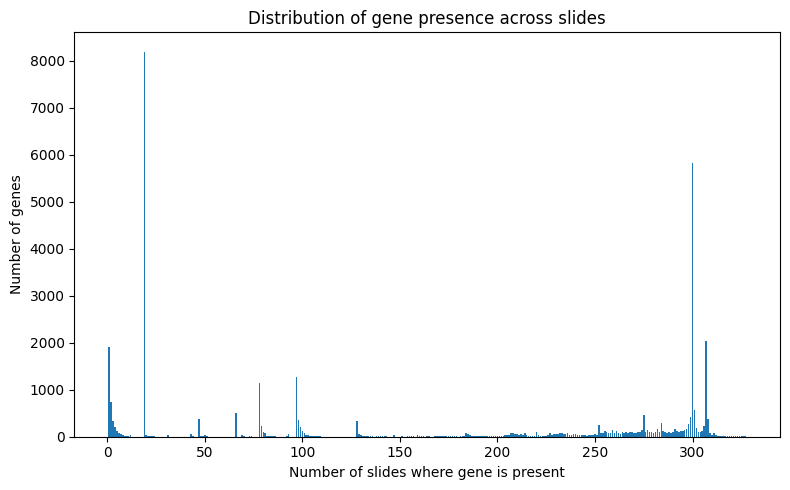

In [21]:
# All slides in meta_csv
plot_gene_presence_distribution(presence_df_filtered)

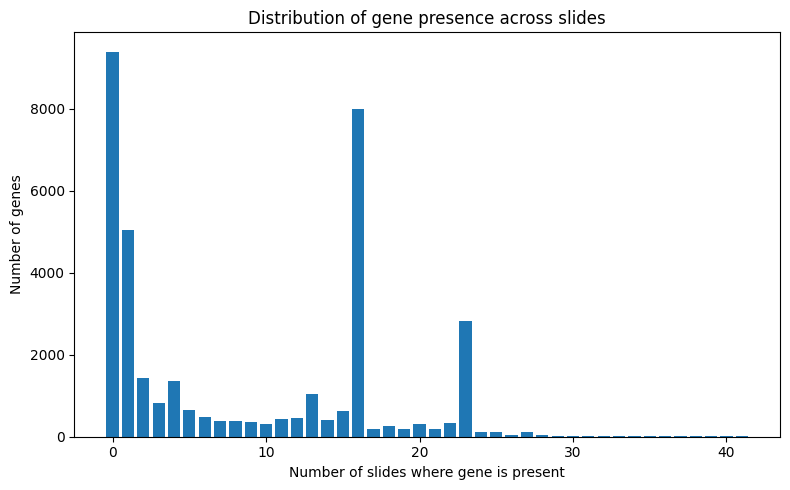

Number of slides: 41


In [22]:
# Slides where 'subset' in meta_csv is 'STHELAR_train' or 'other_technologies'
other_tech_slides = meta_csv.loc[meta_csv['subset'].isin(['STHELAR_train', 'other_technologies']), 'slide_id'].values
plot_gene_presence_distribution(presence_df_filtered.loc[other_tech_slides])
print(f"Number of slides: {len(other_tech_slides)}")

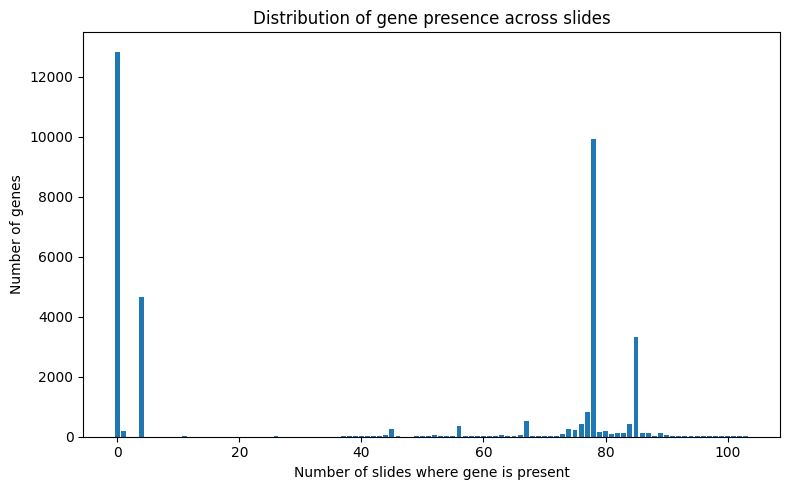

Number of slides: 103


In [23]:
# Slides where 'subset' in meta_csv is 'STHELAR_train' or 'other_magnifications'
other_mag_slides = meta_csv.loc[meta_csv['subset'].isin(['STHELAR_train', 'other_magnifications']), 'slide_id'].values
plot_gene_presence_distribution(presence_df_filtered.loc[other_mag_slides])
print(f"Number of slides: {len(other_mag_slides)}")

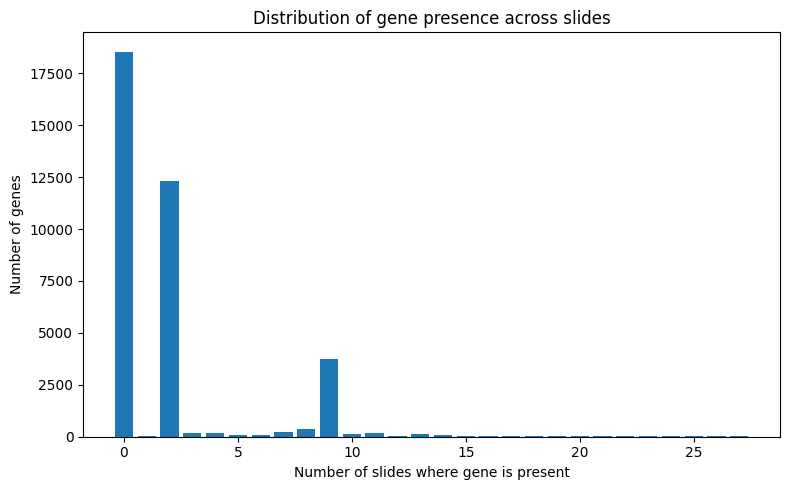

Number of slides: 27


In [24]:
# Slides where 'subset' in meta_csv is 'STHELAR_train' or 'other_organs'
other_org_slides = meta_csv.loc[meta_csv['subset'].isin(['STHELAR_train', 'other_organs']), 'slide_id'].values
plot_gene_presence_distribution(presence_df_filtered.loc[other_org_slides])
print(f"Number of slides: {len(other_org_slides)}")

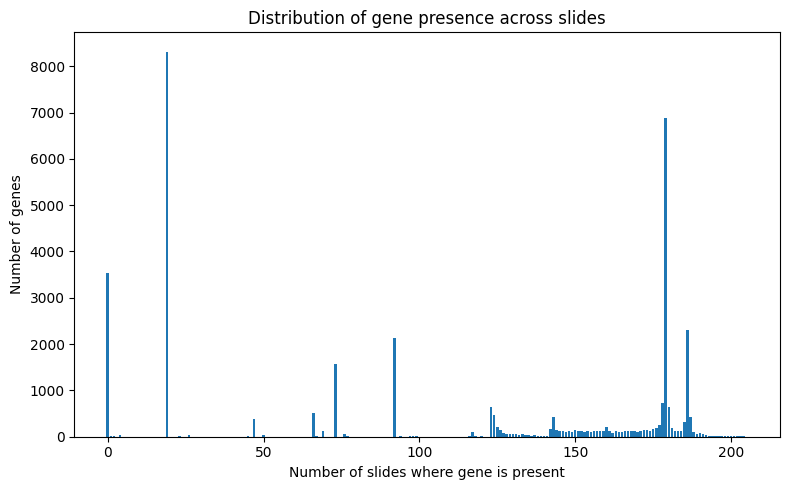

Number of slides: 205


In [25]:
# Slides where 'subset' in meta_csv is 'STHELAR_train' or 'other_preservations'
other_pre_slides = meta_csv.loc[meta_csv['subset'].isin(['STHELAR_train', 'other_preservations']), 'slide_id'].values
plot_gene_presence_distribution(presence_df_filtered.loc[other_pre_slides])
print(f"Number of slides: {len(other_pre_slides)}")

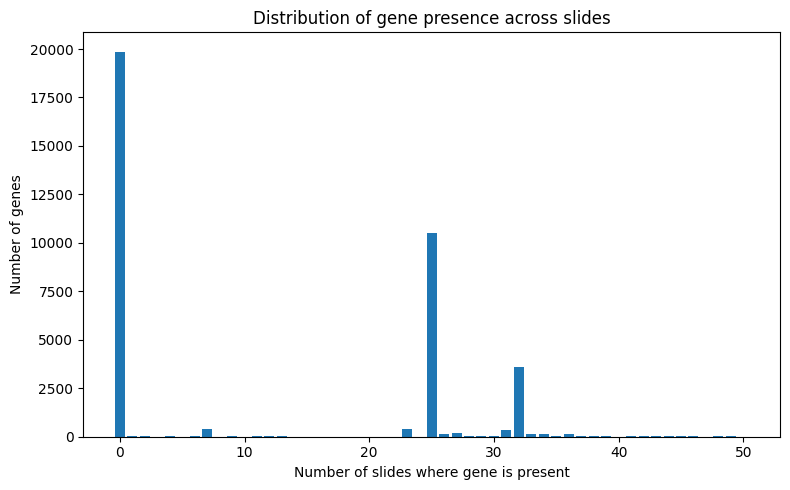

Number of slides: 50


In [26]:
# Slides where 'subset' in meta_csv is 'STHELAR_train' or 'other_species'
other_spe_slides = meta_csv.loc[meta_csv['subset'].isin(['STHELAR_train', 'other_species']), 'slide_id'].values
plot_gene_presence_distribution(presence_df_filtered.loc[other_spe_slides])
print(f"Number of slides: {len(other_spe_slides)}")

In [27]:
# Count values for each tissue_HistoST
meta_csv['tissue_HistoST'].value_counts(dropna=False)

tissue_HistoST
Skin          66
Colon         57
Breast        41
Heart         38
Kidney        36
Uterus        22
Liver         21
Prostate      14
Lung          13
Pancreas       5
Ovary          4
Pancreatic     3
Cervix         2
LymphNode      2
Bladder        2
Tonsil         2
Name: count, dtype: int64

### G_base_1

In [6]:
G_base_id = "G_base_1"

G_base_id: G_base_1
G_base folder: /path/to/ALHENA_data/eval/eval_datasets/st_eval_data/eval_st_ds_ct1_20x_224_o112_1/G_base/G_base_1
Number of genes in G_base: 256


Reading slide gene panels: 100%|██████████| 328/328 [01:13<00:00,  4.45it/s]



Number of slides per subset:
  other_magnifications: 78 slides
  other_preservations: 180 slides
  other_technologies: 16 slides
  other_species: 25 slides
  other_organs: 2 slides
  STHELAR_train: 25 slides
  STHELAR_test: 2 slides


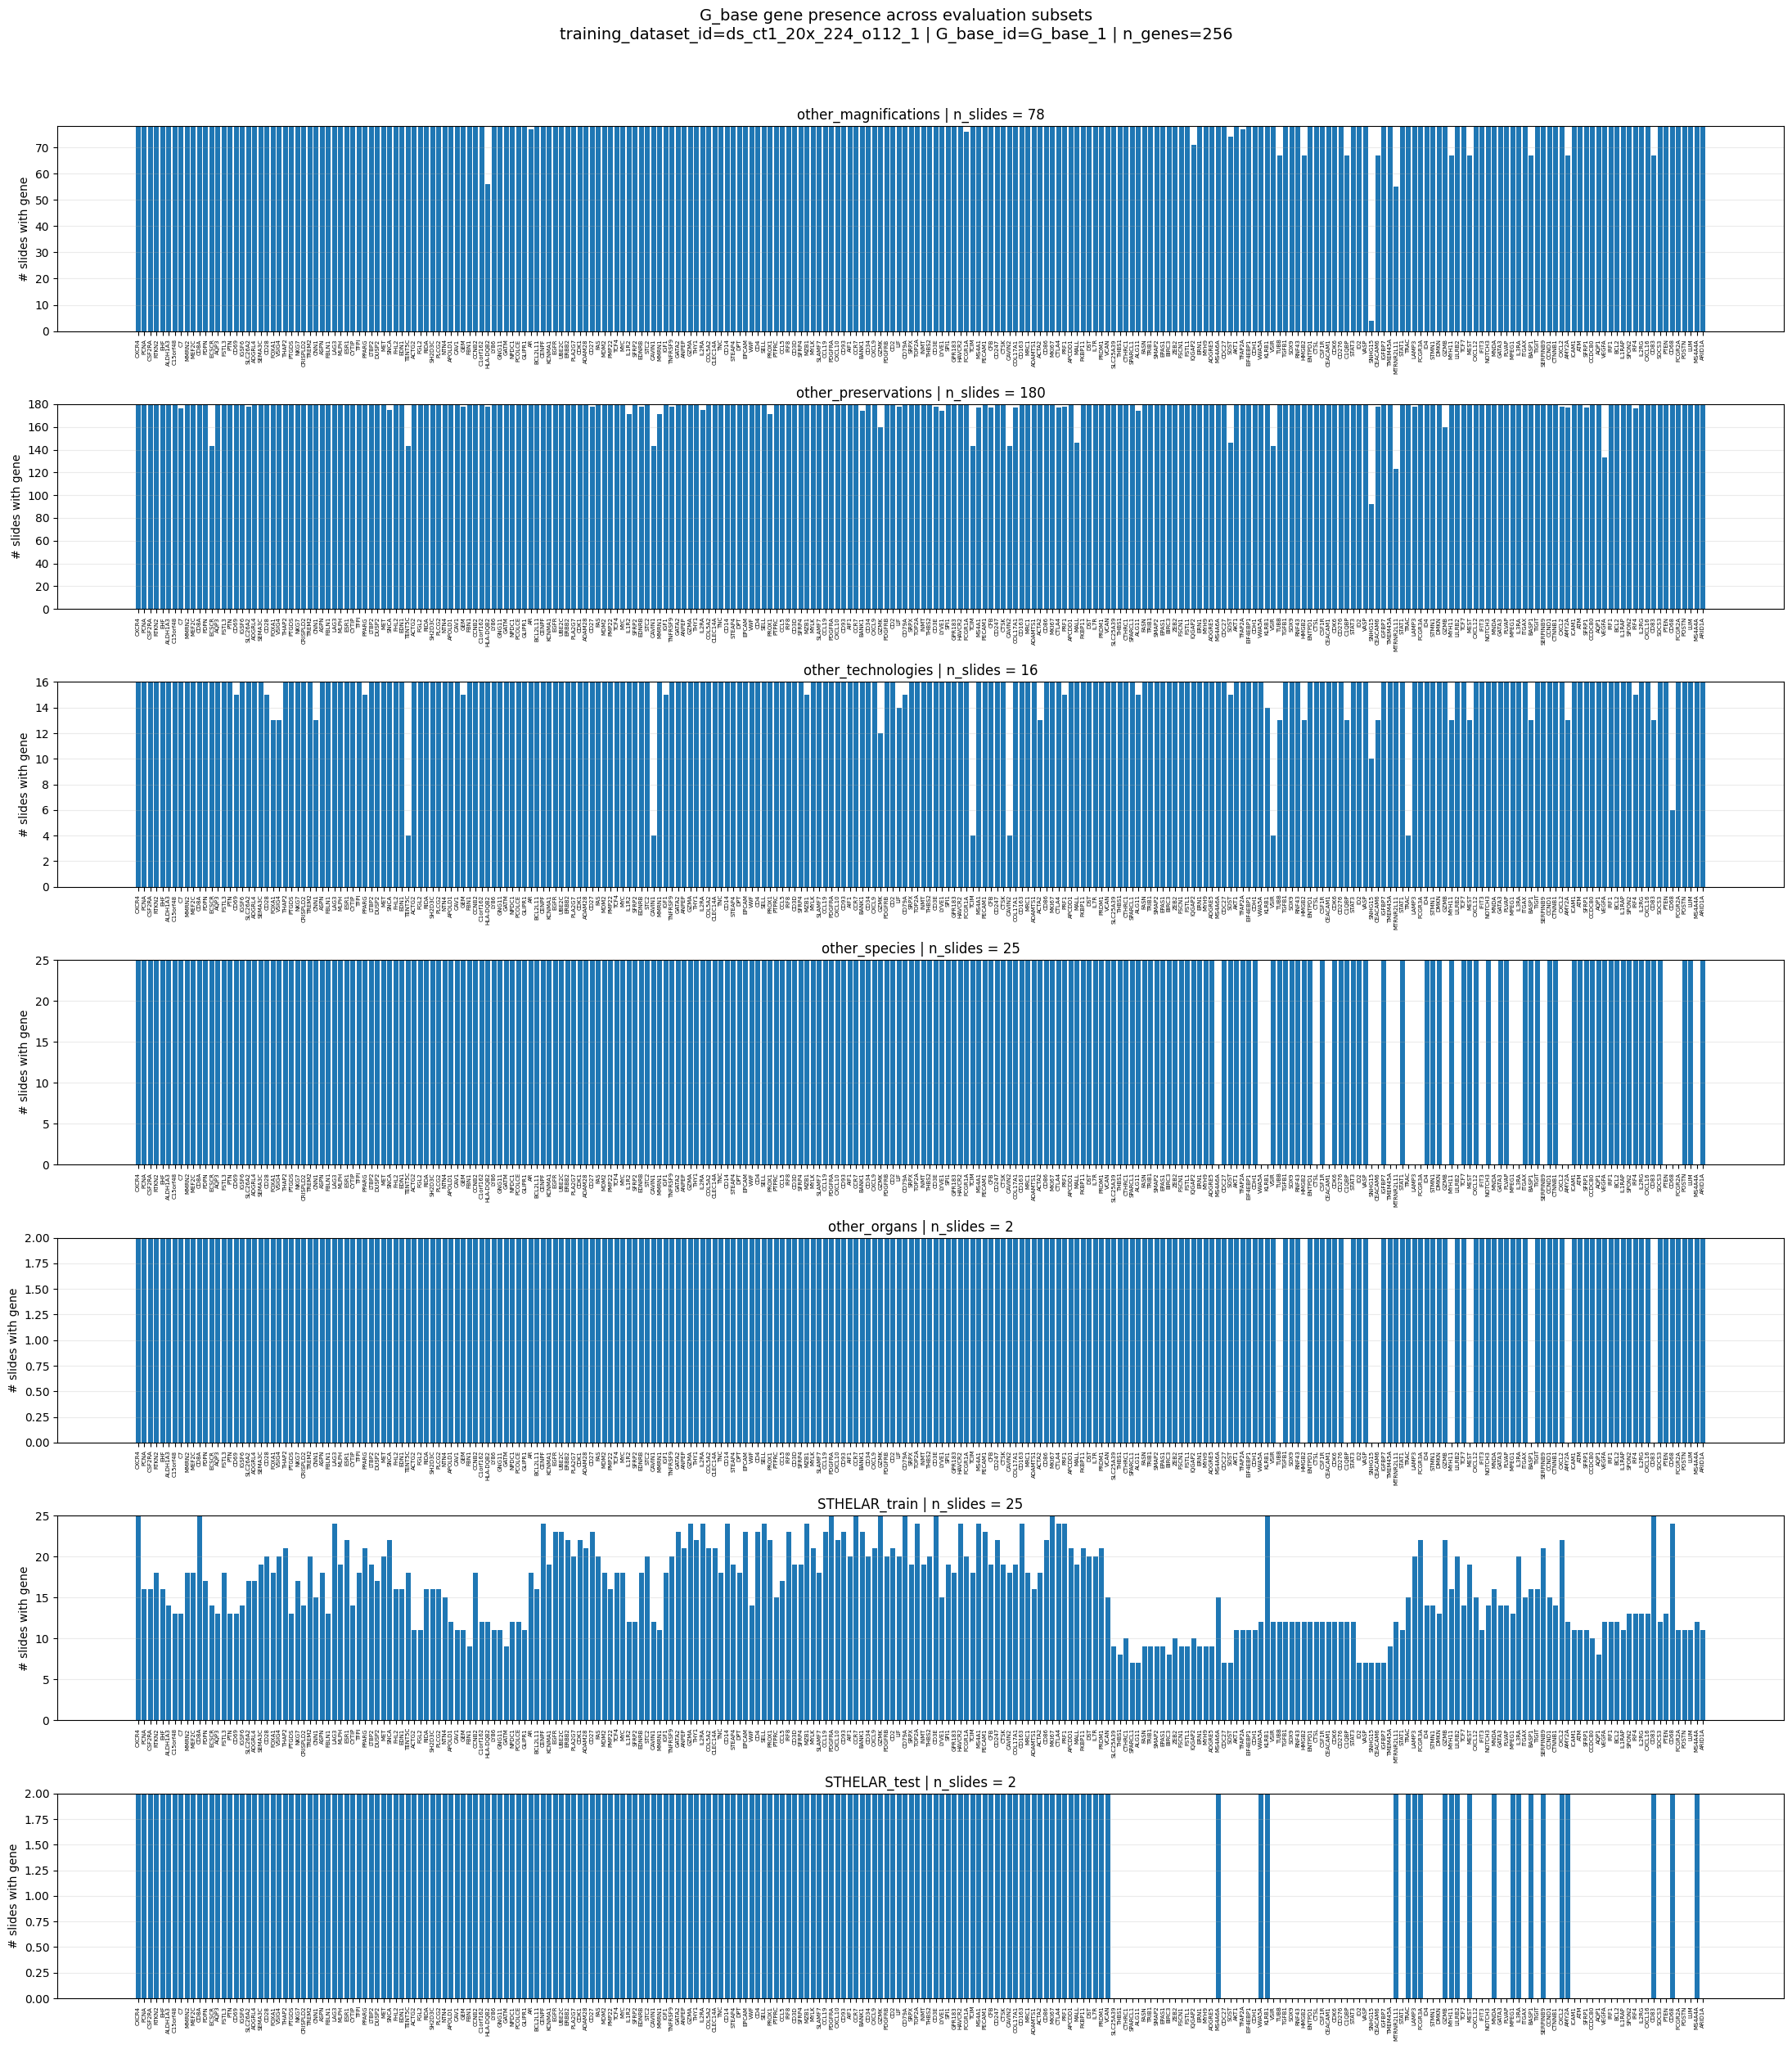

In [7]:
counts_G_base_by_subset = plot_G_base_gene_presence_by_subset(
    training_dataset_id="ds_ct1_20x_224_o112_1",
    G_base_id="G_base_1",
    sort_genes_by="min_presence",
    ncols=1,
    figsize_per_subplot=(22, 3.5),
    xtick_fontsize=5,
)